In [3]:
from sklearn.metrics import accuracy_score
import xgboost as xgb
from sklearn.model_selection import train_test_split
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import os
import geopandas as gpd

## Implementacion modelo XGBOOST 
Se emplea un modelo XGBOOST para rellenar los datos faltos faltantes de la estacion Piedra de Cobre

### Control de calidad
Se chequea la calidad de las series de tiempo y las estaciones aledañas a Piedras de cobre. Se realiza media movil de las estaciones, ploteo estacion vs estacion y curvas de doble masa.

In [68]:
# cargar el cne extraer informacion de las estaciones
cne = gpd.read_file('CNE_actualizado')
cne = cne.set_index('Codigo',drop=True)

In [69]:
# Piedras cobres
path_pidras_cobre = '0022057010-Q_MEDIA_D.csv'
df_piedras_cobre = pd.read_csv(
    path_pidras_cobre,
    index_col=0,
    parse_dates=True
)
df_piedras_cobre = df_piedras_cobre[['valorObservado']]
df_piedras_cobre = df_piedras_cobre.rename(
    columns={'valorObservado':'piedras_cobre'}
)
df_piedras_cobre = df_piedras_cobre.resample('D').mean()

In [70]:
# estaciones aledañas
path_estaciones = 'q_data'
files = os.listdir(path_estaciones)
path_files = [os.path.join(path_estaciones,file) for file in files]

In [71]:
q_prueba = pd.read_csv(path_files[0],index_col=0,parse_dates=True)
q_prueba = q_prueba[['valorObservado']]

In [72]:
def curva_doble_masa(df1,df2):
    df_merge = df1.join(df2,how='inner')
    df_cum_sum = df_merge.cumsum()

    return df_cum_sum

def relacion_q_q(df1,df2):
    df_merge = df1.join(df2,how='inner')
    df_merge['q_q'] = df_merge.iloc[:,0]/df_merge.iloc[:,1]

    return df_merge

def read_file(path,cod):
    df = pd.read_csv(
        path,
        index_col=0,
        parse_dates=True
    )
    estacion = cne.at[cod,'Nombre']
    df = df[['valorObservado']]
    df = df.rename(columns={'valorObservado':estacion})
    df = df.resample('D').mean()
    return df

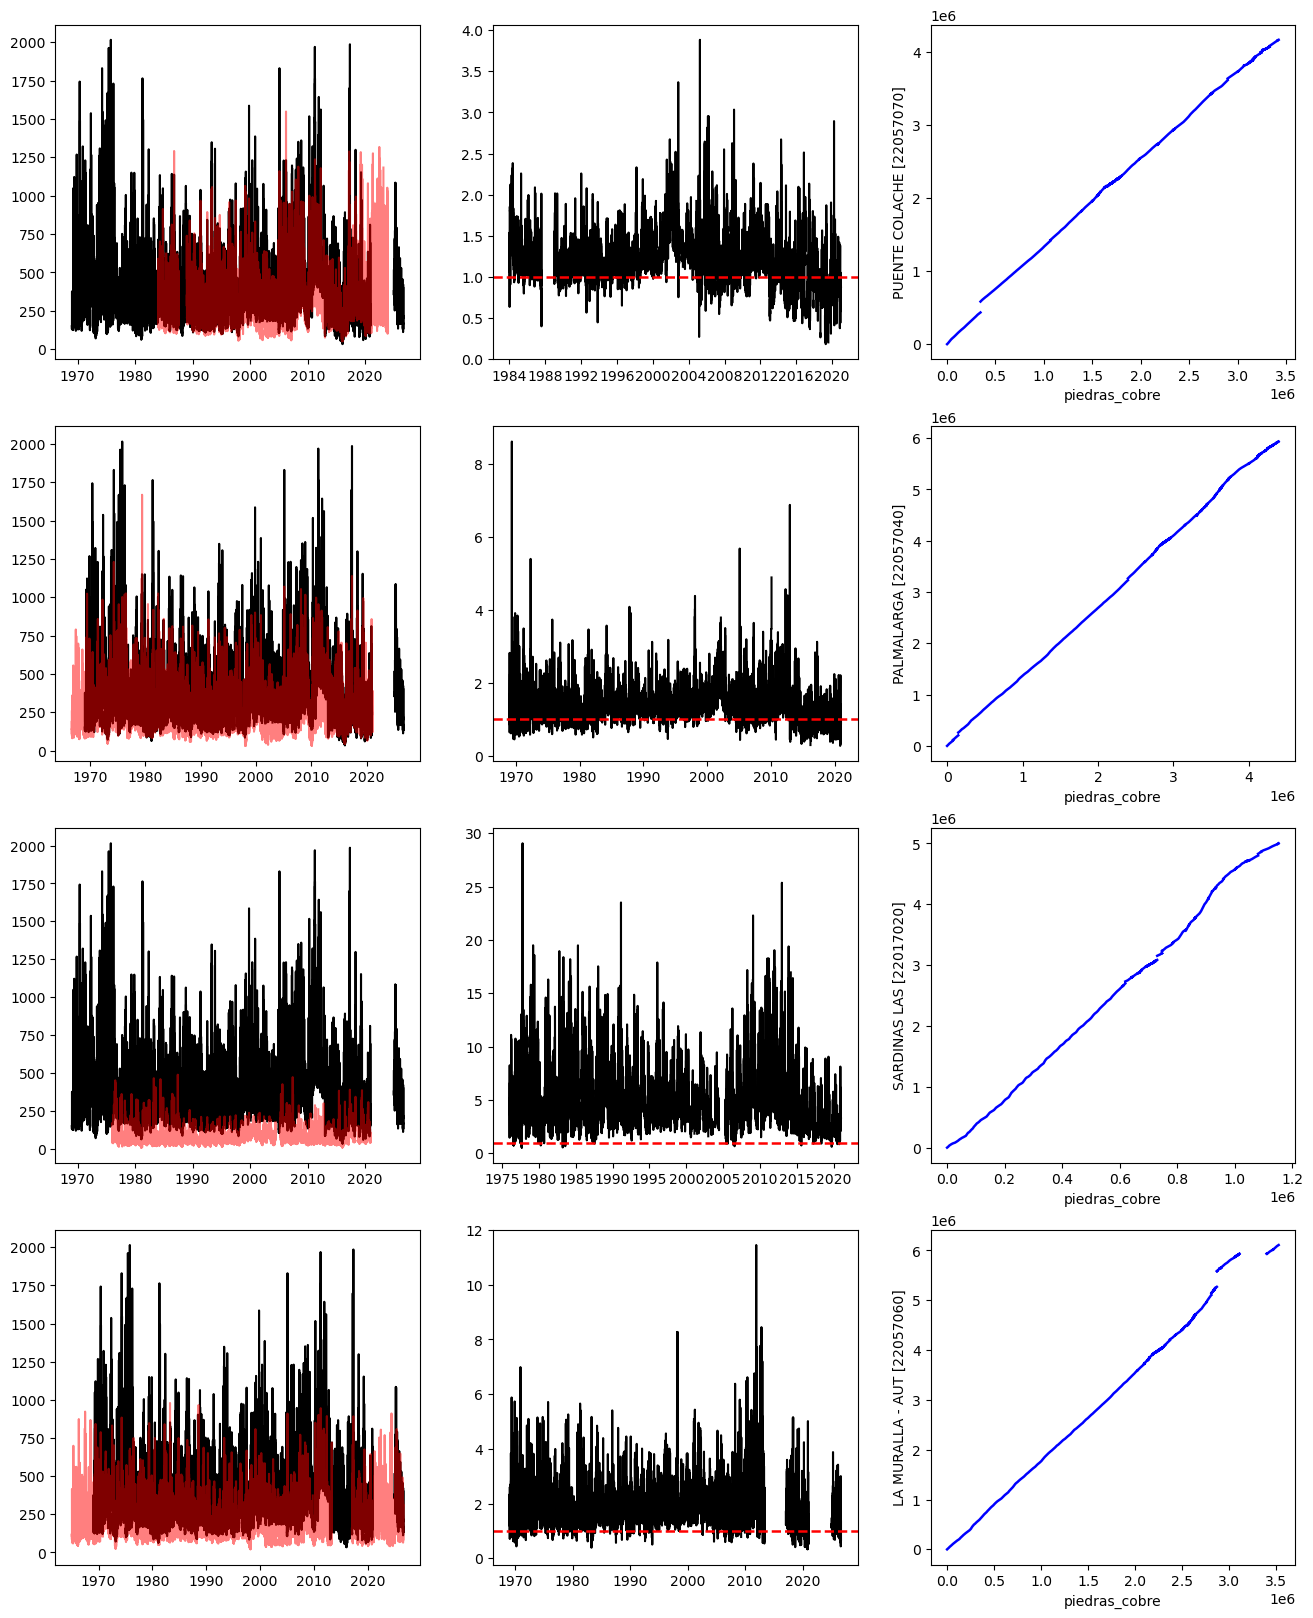

In [73]:
figs, axes = plt.subplots(4,3,figsize=(16,20))

fila = 0
for idx,file in enumerate(path_files):
    # lectura del df
    cod = files[idx][2:].split('-')[0]
    df = read_file(file,cod)
    # genera comparaciones

    # Comparacion series de tiempo
    axes[fila,0].plot(
        df_piedras_cobre,
        color='black',
        label='piedras_cobre'
    )
    axes[fila,0].plot(
        df,
        color='red',
        label=df.columns[0],
        alpha=0.5
    )
    # relacion q_q estacion
    df_relacion = relacion_q_q(df_piedras_cobre,df)
    axes[fila,1].plot(
        df_relacion['q_q'],
        color='black'
    )

    axes[fila,1].axhline(y=1.0,color='red',linewidth=1.8,linestyle='--')
    # curvas de doble masa
    df_curva = curva_doble_masa(df_piedras_cobre,df)
    y = df_curva.iloc[:,0]
    x = df_curva.iloc[:,1]
    axes[fila,2].plot(x,y,color='blue',linewidth=1.8)
    axes[fila,2].set_xlabel(df_curva.columns[0])
    axes[fila,2].set_ylabel(df_curva.columns[1])   

    fila += 1 

### Autocorrelacion entre estaciones
Se mantienen unicamente las estaciones de Piedras de Cobre y La Muralla

<Axes: >

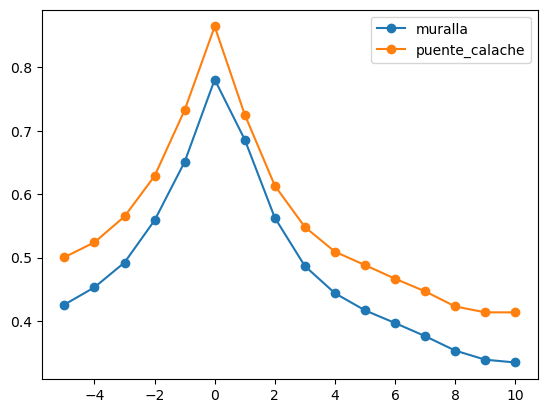

In [81]:
path_muralla = 'q_data/0022057060-Q_MEDIA_D.csv'
path_pte_colache = 'q_data/0022057070-Q_MEDIA_D.csv'
# lectura de datos
df_muralla = read_file(path_muralla,'22057060')
df_pte_colache = read_file(path_pte_colache,'22057070')

def ccf(pc, vec, lags=range(-5, 11)):
    """corr(vec(t-k), pc(t)). k>0: la vecina va adelante."""
    out = {}
    for k in lags:
        out[k] = pc.corr(vec.shift(k))   # pandas ignora pares con NaN
    return pd.Series(out)

# usar log Q y quitar el ciclo estacional
def anomalia(q):
    lq = np.log(q.where(q > 0))
    clim = lq.groupby(lq.index.dayofyear).transform("mean")
    return lq - clim

pc_a  = anomalia(df_piedras_cobre.iloc[:,0])
mur_a = anomalia(df_muralla.iloc[:,0])
cal_a = anomalia(df_pte_colache.iloc[:,0])

res = pd.DataFrame({"muralla": ccf(pc_a, mur_a),
                    "puente_calache": ccf(pc_a, cal_a)})
res.plot(marker="o")

In [80]:
res

,muralla,puente_calache
-5,0.426000,0.426000
-4,0.453251,0.453251
-3,0.492344,0.492344
-2,0.558723,0.558723
-1,0.650804,0.650804
0,0.780599,0.780599
1,0.685964,0.685964
2,0.562836,0.562836
3,0.486747,0.486747
4,0.443927,0.443927
